# Mall dataset exploration

[Mall dataset](https://personal.ie.cuhk.edu.hk/~ccloy/downloads_mall_dataset.html) (Chen, Loy, Gong, Xiang; BMVC 2012 / CVPR 2013): 2000 frames from one fixed surveillance camera over a shopping-mall walkway, annotated with **one head point per person**. It was made for crowd counting. Our task is person presence ("is anyone in view?"), so the useful question here is how much of the data could serve as person / empty examples and what traps there are.

Files in `mall_dataset/`: `frames/seq_000001.jpg … seq_002000.jpg`, `mall_gt.mat` (`frame{i}.loc` = head points, `count`), `perspective_roi.mat` (annotation `roi.mask` and perspective map `pMapN`), `mall_feat.mat` (hand-crafted counting features from the papers, not used here). Loading helpers are in `semwisp/mall.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../..').resolve()))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from semwisp.mall import ROOT, frame_path, load_gt, load_roi, person_boxes, BLACK_ROWS
from semwisp.piropo import load_gray

points, counts = load_gt()
roi, pmap = load_roi()
im0 = Image.open(frame_path(1))
print(f'{len(points)} frames, {im0.size[0]}x{im0.size[1]} {im0.mode}; {counts.sum()} head points')
print(f'people per frame: min {counts.min()}, median {np.median(counts):.0f}, mean {counts.mean():.1f}, max {counts.max()}')
print(f'ROI covers {roi.mean():.1%} of the image; head points outside ROI: {sum((~roi[np.clip(p[:,1].astype(int),0,479), np.clip(p[:,0].astype(int),0,639)]).sum() for p in points)}')

2000 frames, 640x480 RGB; 62315 head points
people per frame: min 13, median 31, mean 31.2, max 53
ROI covers 90.2% of the image; head points outside ROI: 1


## Crowd size over time

Every frame is crowded: no frame comes close to empty, so whole frames cannot give negatives. The count changes slowly, which fits a low frame rate (under 2 fps according to the paper) with strongly correlated neighbours.

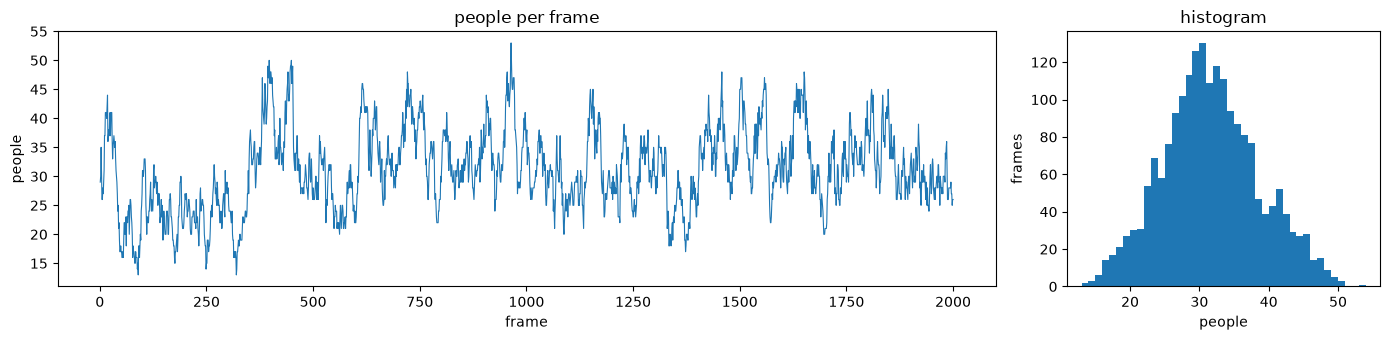

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw=dict(width_ratios=[3, 1]))
ax[0].plot(np.arange(1, len(counts) + 1), counts, lw=0.8)
ax[0].set(xlabel='frame', ylabel='people', title='people per frame')
ax[1].hist(counts, bins=range(counts.min(), counts.max() + 2))
ax[1].set(xlabel='people', ylabel='frames', title='histogram')
plt.tight_layout(); plt.show()

## Sample frames with annotations and ROI

Red dots: head points. Yellow line: border of the annotation ROI. Annotators only marked people inside the ROI, so a person standing outside it (the shop fronts at the top left and top right) is unlabelled. The top-left shop window also has **mannequins** that look like people, which is a hard negative for a presence detector. Rows 0-15 are a black band.

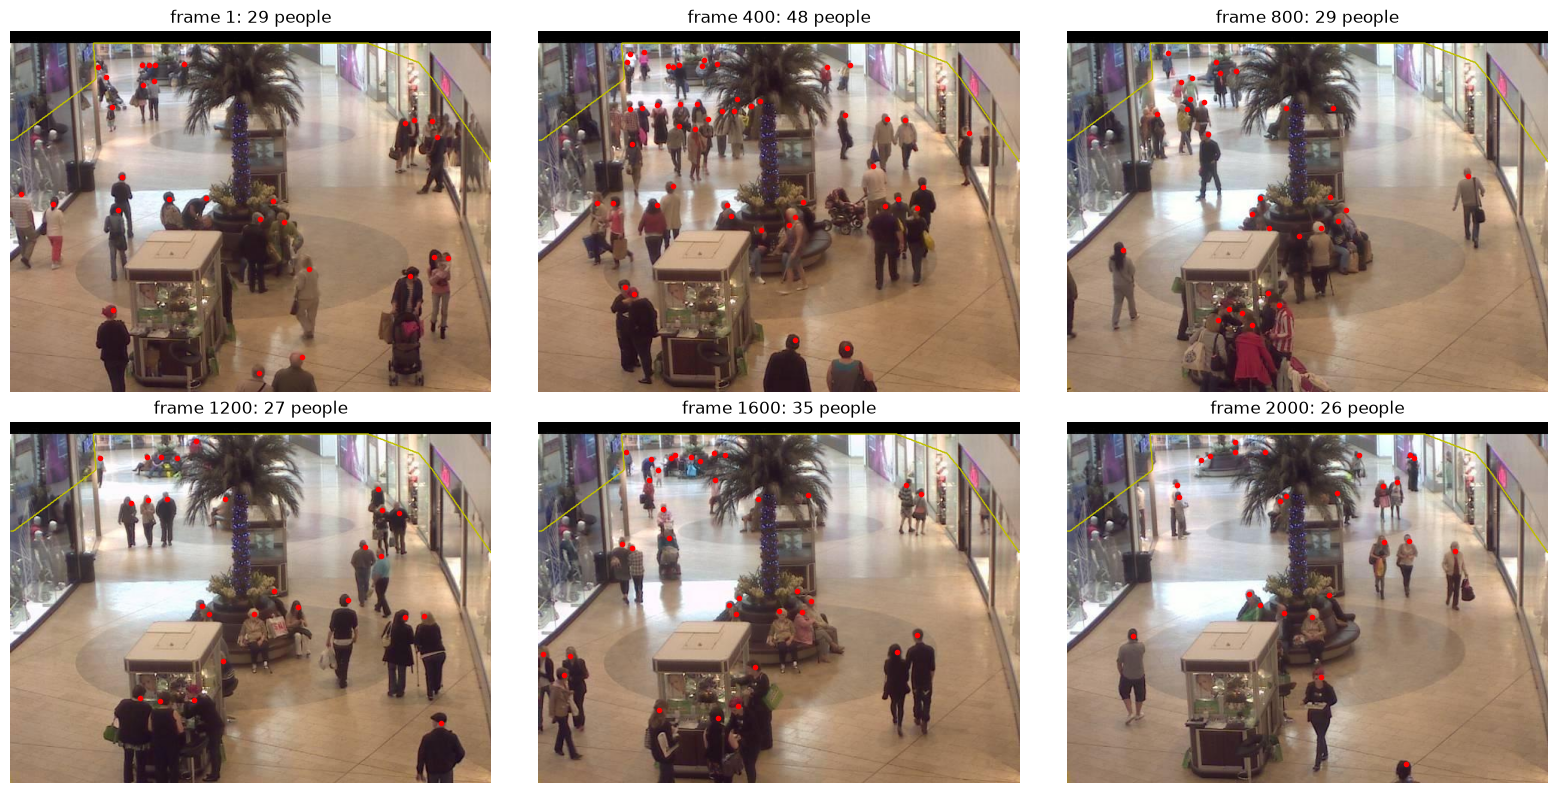

In [3]:
def show(ax, i, boxes=False):
    ax.imshow(Image.open(frame_path(i)))
    p = points[i - 1]
    ax.plot(p[:, 0], p[:, 1], 'r.', ms=6)
    ax.contour(roi, [0.5], colors='y', linewidths=1)
    if boxes:
        for x0, y0, x1, y1 in person_boxes(p):
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='r', lw=0.7))
    ax.set_title(f'frame {i}: {counts[i - 1]} people'); ax.axis('off')

fig, axs = plt.subplots(2, 3, figsize=(16, 8))
for ax, i in zip(axs.ravel(), np.linspace(1, 2000, 6).astype(int)):
    show(ax, i)
plt.tight_layout(); plt.show()

## Where people are

Heat map of all head points. Most of the walkway is busy. The bright spots are people who sit or stand still for a long time (benches around the planter, the kiosk), so the same person is counted in hundreds of frames. The upper part of the image is far from the camera and people there are small and dense.

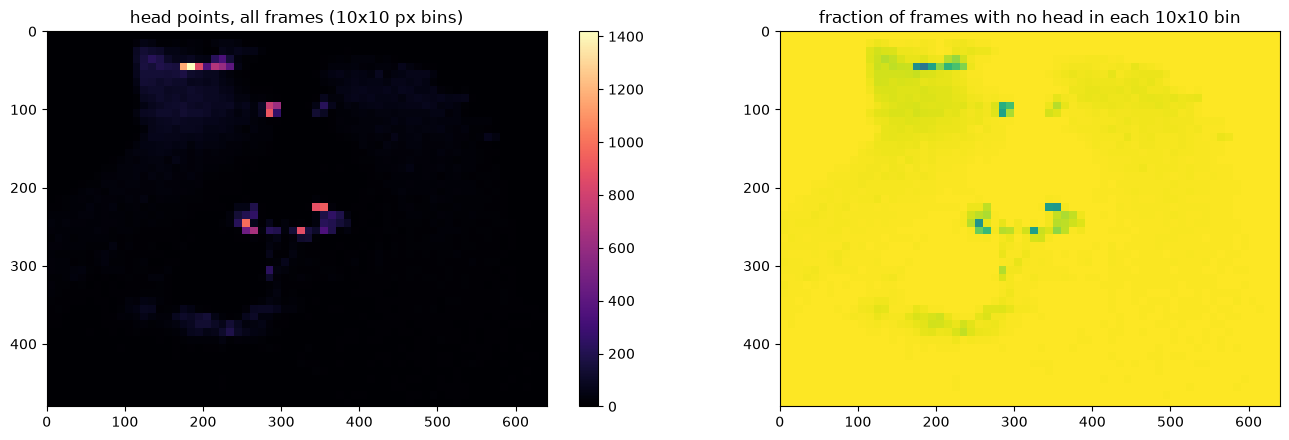

In [4]:
allp = np.concatenate(points)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
h = ax[0].hist2d(allp[:, 0], allp[:, 1], bins=[64, 48], range=[[0, 640], [0, 480]], cmap='magma')
ax[0].invert_yaxis(); ax[0].set_aspect('equal'); ax[0].set_title('head points, all frames (10x10 px bins)')
plt.colorbar(h[3], ax=ax[0])
occ = np.zeros((48, 64))
for p in points:
    xi = np.clip((p[:, 0] // 10).astype(int), 0, 63); yi = np.clip((p[:, 1] // 10).astype(int), 0, 47)
    o = np.zeros((48, 64), bool); o[yi, xi] = True; occ += o
ax[1].imshow(1 - occ / len(points), cmap='viridis', vmin=0, vmax=1, extent=[0, 640, 480, 0])
ax[1].set_title('fraction of frames with no head in each 10x10 bin')
plt.tight_layout(); plt.show()

## Perspective and person size

`pMapN` depends only on the row y. People measure roughly 20 px tall near the top of the image and 140 px near the bottom. `semwisp.mall.person_height` is a hand-fitted linear model (`0.33*y + 5`), drawn below as boxes around each head point. It errs on the large side on purpose: the crop labels use it to call a crop empty only when no estimated body reaches into it.

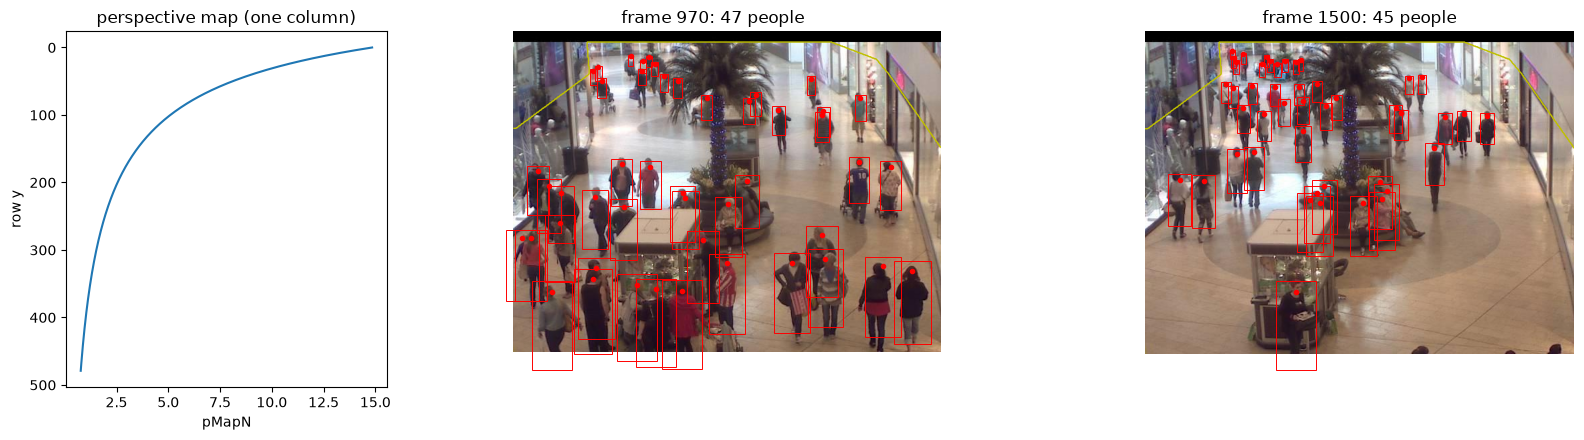

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw=dict(width_ratios=[1, 2, 2]))
axs[0].plot(pmap[:, 0], np.arange(480)); axs[0].invert_yaxis()
axs[0].set(xlabel='pMapN', ylabel='row y', title='perspective map (one column)')
show(axs[1], 970, boxes=True); show(axs[2], 1500, boxes=True)
plt.tight_layout(); plt.show()

## Temporal correlation

Mean absolute gray-level difference between consecutive frames, compared with frames 50 and 500 apart. Consecutive frames differ by about 12 gray levels on average, against about 20-22 for frames 50 or 500 apart. At this low frame rate people move a lot between frames, but the background and anyone standing still repeat, so a train/test split should still use **contiguous blocks of frames**, as with PIROPO. No frame fails the PIROPO corruption test (mean gray level more than 15 from the median).

lag    1: mean abs difference 11.64 gray levels
lag    5: mean abs difference 16.95 gray levels
lag   50: mean abs difference 20.29 gray levels
lag  500: mean abs difference 22.00 gray levels


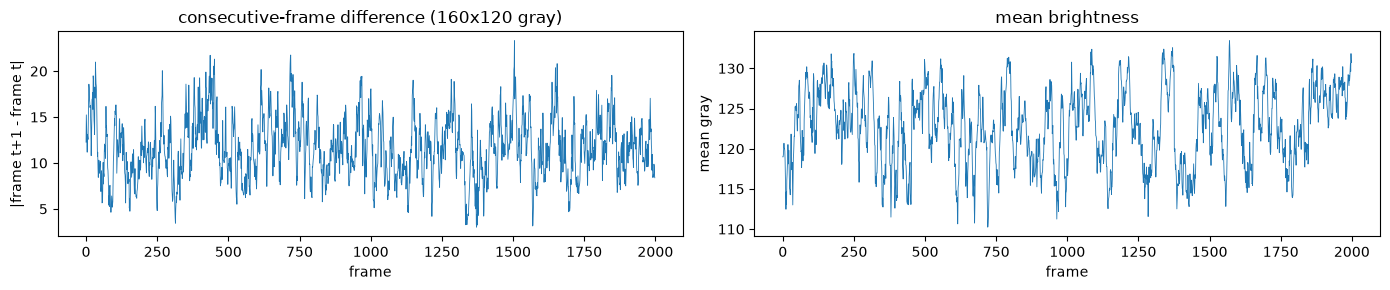

frames with mean gray > 15 from median (PIROPO corruption test): []


In [7]:
G = np.stack([load_gray(frame_path(i)) for i in range(1, 2001)]).astype(np.float32)
d1 = np.abs(np.diff(G, axis=0)).mean((1, 2))
for lag in [1, 5, 50, 500]:
    d = np.abs(G[lag:] - G[:-lag]).mean((1, 2))
    print(f'lag {lag:4d}: mean abs difference {d.mean():5.2f} gray levels')
m = G.mean((1, 2))
fig, ax = plt.subplots(1, 2, figsize=(14, 3))
ax[0].plot(d1, lw=0.6); ax[0].set(xlabel='frame', ylabel='|frame t+1 - frame t|', title='consecutive-frame difference (160x120 gray)')
ax[1].plot(m, lw=0.6); ax[1].set(xlabel='frame', ylabel='mean gray', title='mean brightness')
plt.tight_layout(); plt.show()
bad = np.abs(m - np.median(m)) > 15
print('frames with mean gray > 15 from median (PIROPO corruption test):', np.where(bad)[0] + 1)

## At WISP resolution

The whole frame at 160×120 grayscale (the WISP input) and as a 16×12 thumbnail. Far-away people are only a pixel or two tall at 160×120, which is another reason to work on crops: a 3×3 tile of 213×160 px resizes to 160×120 with almost no loss.

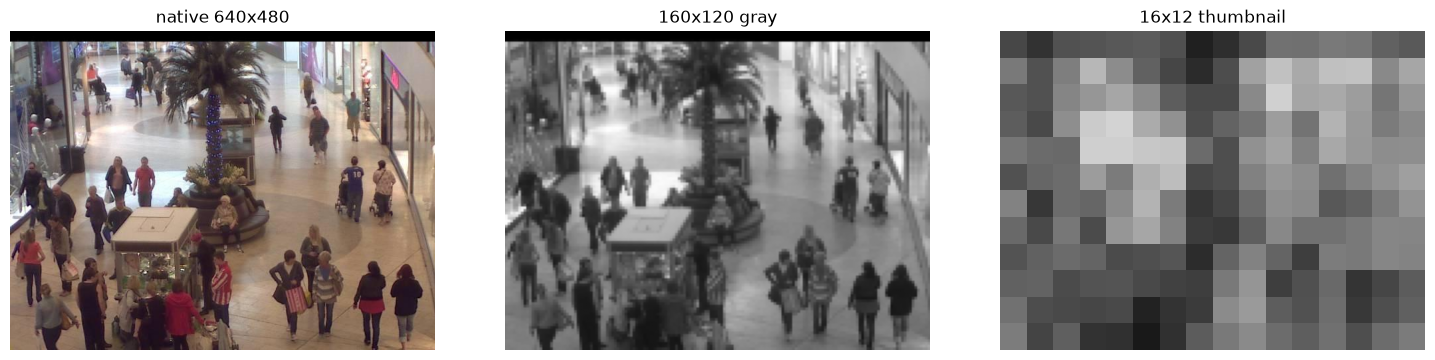

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
axs[0].imshow(Image.open(frame_path(970))); axs[0].set_title('native 640x480')
axs[1].imshow(G[969], cmap='gray', vmin=0, vmax=255); axs[1].set_title('160x120 gray')
axs[2].imshow(G[969].reshape(12, 10, 16, 10).mean((1, 3)), cmap='gray', vmin=0, vmax=255); axs[2].set_title('16x12 thumbnail')
for a in axs: a.axis('off')
plt.tight_layout(); plt.show()

## Summary

- 2000 frames, 640×480 RGB, one camera, 13–53 people in every frame (mean 31). Whole frames are never empty.
- Labels are head points inside the ROI only. Areas outside it (top-left and top-right shop fronts) contain unannotated people and mannequins.
- People sit still for long stretches near the planter and kiosk, so some regions are occupied almost all the time.
- Neighbouring frames are correlated (half the pixel difference of distant frames) but not near-duplicates; still split by contiguous frame blocks. No corrupted frames were found.
- For presence detection, the frames are split into 3×3 sub-frames with person / empty / ambiguous labels: see `cropped/` (`make_crops.py`, `view_crops.ipynb`).